In [1]:
import os
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import RDKit

try:
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Crippen, Lipinski

    RDKIT_AVAILABLE = True

    print("RDKit imported successfully!")

except ImportError:

    RDKIT_AVAILABLE = False

    print("RDKit is not installed.")
    print("Install using: %pip install rdkit")

RDKit imported successfully!


In [2]:
ligands_df = pd.DataFrame({

    "Molecule_ID": [
        "Ligand_01",
        "Ligand_02",
        "Ligand_03",
        "Ligand_04",
        "Ligand_05",
        "Ligand_06"
    ],

    "SMILES": [
        "CCO",
        "CC(=O)Oc1ccccc1C(=O)O",
        "CCN(CC)CC",
        "c1ccccc1",
        "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
        "CCOC(=O)c1ccccc1"
    ]

})

print("LIGAND DATASET")

display(ligands_df)

LIGAND DATASET


,Molecule_ID,SMILES
0,Ligand_01,CCO
1,Ligand_02,CC(=O)Oc1ccccc1C(=O)O
2,Ligand_03,CCN(CC)CC
3,Ligand_04,c1ccccc1
4,Ligand_05,CC(C)Cc1ccc(cc1)C(C)C(=O)O
5,Ligand_06,CCOC(=O)c1ccccc1


In [3]:
if RDKIT_AVAILABLE:

    rows = []

    for index, row in ligands_df.iterrows():

        molecule = Chem.MolFromSmiles(row["SMILES"])

        if molecule:

            rows.append({

                "Molecule_ID": row["Molecule_ID"],

                "MolWt": Descriptors.MolWt(molecule),

                "LogP": Crippen.MolLogP(molecule),

                "HBD": Lipinski.NumHDonors(molecule),

                "HBA": Lipinski.NumHAcceptors(molecule),

                "TPSA": Descriptors.TPSA(molecule),

                "RotatableBonds": Lipinski.NumRotatableBonds(molecule)

            })


    desc = pd.DataFrame(rows)

    print("MOLECULAR PROPERTIES")

    display(desc)

else:

    print("RDKit is required for this calculation.")

MOLECULAR PROPERTIES


,Molecule_ID,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds
0,Ligand_01,46.069,-0.0014,1,1,20.23,0
1,Ligand_02,180.159,1.3101,1,3,63.60,2
2,Ligand_03,101.193,1.3481,0,1,3.24,3
3,Ligand_04,78.114,1.6866,0,0,0.00,0
4,Ligand_05,206.285,3.0732,1,1,37.30,4
5,Ligand_06,150.177,1.8633,0,2,26.30,2


In [4]:
if RDKIT_AVAILABLE:

    filtered = desc[
        (desc["MolWt"] <= 500) &
        (desc["LogP"] <= 5) &
        (desc["HBD"] <= 5) &
        (desc["HBA"] <= 10)
    ]

    print("LIPINSKI FILTER RESULTS")

    print("Total Ligands:", len(desc))

    print("Candidates Passing Filter:", len(filtered))

    display(filtered)

else:

    print("RDKit is required.")

LIPINSKI FILTER RESULTS
Total Ligands: 6
Candidates Passing Filter: 6


,Molecule_ID,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds
0,Ligand_01,46.069,-0.0014,1,1,20.23,0
1,Ligand_02,180.159,1.3101,1,3,63.60,2
2,Ligand_03,101.193,1.3481,0,1,3.24,3
3,Ligand_04,78.114,1.6866,0,0,0.00,0
4,Ligand_05,206.285,3.0732,1,1,37.30,4
5,Ligand_06,150.177,1.8633,0,2,26.30,2


In [5]:
if RDKIT_AVAILABLE:

    # Select molecular properties

    columns = [
        "MolWt",
        "LogP",
        "HBD",
        "HBA",
        "TPSA",
        "RotatableBonds"
    ]

    # First ligand as reference

    reference = desc.iloc[0][columns]

    # Calculate scale for normalization

    scale = (desc[columns].max() - desc[columns].min()).replace(0, 1)

    distances = []

    for index, row in desc.iterrows():

        difference = (row[columns] - reference) / scale

        distance = np.sqrt(np.sum(difference ** 2))

        distances.append(distance)


    # Calculate screening score

    desc["Descriptor_Distance"] = distances

    desc["Screening_Score"] = 1 / (1 + desc["Descriptor_Distance"])


    # Sort ligands by score

    screening = desc.sort_values(
        "Screening_Score",
        ascending=False
    )

    print("VIRTUAL SCREENING RESULTS")

    display(
        screening[
            ["Molecule_ID", "Descriptor_Distance", "Screening_Score"]
        ]
    )

else:

    print("RDKit is required.")

VIRTUAL SCREENING RESULTS


,Molecule_ID,Descriptor_Distance,Screening_Score
0,Ligand_01,0.000000,1.000000
3,Ligand_04,1.246478,0.445141
2,Ligand_03,1.394593,0.417607
1,Ligand_02,1.428939,0.411702
5,Ligand_06,1.469790,0.404893
4,Ligand_05,1.752723,0.363277


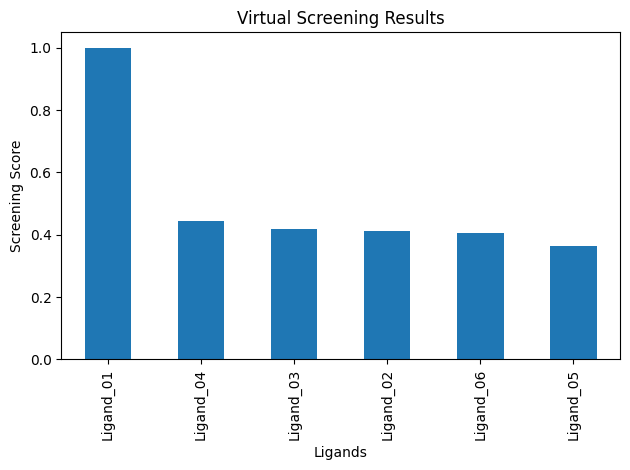

In [6]:
if RDKIT_AVAILABLE:

    screening.plot(
        x="Molecule_ID",
        y="Screening_Score",
        kind="bar",
        legend=False
    )

    plt.title("Virtual Screening Results")

    plt.xlabel("Ligands")

    plt.ylabel("Screening Score")

    plt.tight_layout()

    plt.show()

In [7]:
# Check whether AutoDock Vina is installed

vina = shutil.which("vina")

if vina:

    print("AutoDock Vina is installed.")

    print("Vina Location:", vina)

else:

    print("AutoDock Vina is not installed.")

AutoDock Vina is not installed.


In [8]:
# Protein file

receptor = "receptor.pdbqt"

# Ligand file

ligand = "ligand_01.pdbqt"


# Docking box center

center_x = 0.0
center_y = 0.0
center_z = 0.0


# Docking box dimensions

size_x = 20.0
size_y = 20.0
size_z = 20.0


print("RECEPTOR:", receptor)

print("LIGAND:", ligand)

print("DOCKING BOX CENTER:", center_x, center_y, center_z)

print("DOCKING BOX SIZE:", size_x, size_y, size_z)

RECEPTOR: receptor.pdbqt
LIGAND: ligand_01.pdbqt
DOCKING BOX CENTER: 0.0 0.0 0.0
DOCKING BOX SIZE: 20.0 20.0 20.0


In [9]:
import subprocess

if (
    vina and
    os.path.exists(receptor) and
    os.path.exists(ligand)
):

    command = [

        vina,

        "--receptor", receptor,

        "--ligand", ligand,

        "--center_x", str(center_x),
        "--center_y", str(center_y),
        "--center_z", str(center_z),

        "--size_x", str(size_x),
        "--size_y", str(size_y),
        "--size_z", str(size_z),

        "--out", "docked_ligand.pdbqt",

        "--log", "docking.log"
    ]


    print("Starting Molecular Docking...")

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )


    if result.returncode == 0:

        print("Docking Completed Successfully!")

        print(result.stdout)

    else:

        print("Docking Failed!")

        print(result.stderr)

else:

    print("Docking cannot be performed.")

    print("Check Vina installation and PDBQT files.")

Docking cannot be performed.
Check Vina installation and PDBQT files.


In [10]:
print("=" * 50)

print("MOLECULAR DOCKING AND VIRTUAL SCREENING")

print("=" * 50)

if RDKIT_AVAILABLE:

    print("Total Ligands Analyzed:", len(desc))

    print("Candidates Passing Lipinski Filter:", len(filtered))

    print("Virtual Screening Completed")

else:

    print("RDKit calculations were not performed.")

if vina:

    print("AutoDock Vina: Available")

else:

    print("AutoDock Vina: Not Available")

print("\nAnalysis Completed!")

print("=" * 50)

MOLECULAR DOCKING AND VIRTUAL SCREENING
Total Ligands Analyzed: 6
Candidates Passing Lipinski Filter: 6
Virtual Screening Completed
AutoDock Vina: Not Available

Analysis Completed!
